# Commodity futures time-series momentum: the narrative

This notebook walks the results of the pipeline. It imports the project's code from `src/`
and loads what `make all` wrote to `results/` and `figures/`; nothing is computed here that
is not already in the pipeline, and nothing touches the network. Run `make all` first,
then `make notebook` executes this file headless (CI does the same).

The README carries the full write-up, the inference and the limitations; this is the tour.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display

from src.config import load_config
from src.metrics import max_drawdown, sharpe
from src.plots import drawdown_curve, wealth_index
from src.robustness import default_spec, matches, trial_stats
from src.subperiods import calendar_year_returns

cfg = load_config(ROOT / "config" / "default.yaml")
RESULTS = ROOT / cfg.paths.results_dir
FIGURES = ROOT / cfg.paths.figures_dir
pd.set_option("display.precision", 3)

## 1. The configuration: fixed a priori, never tuned

Every parameter comes from `config/default.yaml`. The headline uses the defaults below; the
other values in the robustness grid exist to show sensitivity, not to pick from.

In [2]:
pd.Series(
    {
        "lookback (days)": cfg.signal.lookback,
        "skip (days)": cfg.signal.skip,
        "vol window (days)": cfg.sizing.vol_window,
        "vol estimator": cfg.sizing.vol_estimator,
        "asset vol target": cfg.sizing.sigma_target_asset,
        "portfolio vol target": cfg.sizing.sigma_target_portfolio,
        "leverage cap": cfg.sizing.leverage_cap,
        "rebalance": cfg.execution.rebalance,
        "execution lag (days)": cfg.execution.lag,
        "cost (bps, one way)": cfg.costs.cost_bps,
        "return clip": cfg.data.clip,
        "forward-fill limit (days)": cfg.data.ffill_limit,
    },
    name="default",
).to_frame()

,default
lookback (days),252
skip (days),0
vol window (days),60
vol estimator,rolling
asset vol target,0.1
portfolio vol target,0.1
leverage cap,3.0
rebalance,monthly
execution lag (days),1
"cost (bps, one way)",5.0


## 2. The data: what passed the gate and what was cleaned

The quality gate, the filled gaps and the clipped returns are reported by the panel stage.

In [3]:
display(Markdown((RESULTS / "data_quality.md").read_text()))

# Data quality report

Calendar: 1997-10-29 to 2026-09-07, 7268 rows.

## Instruments

| Ticker | First | Last | Rows | Filled | Fill % | Longest gap | Years | Clipped days | Verdict | Reasons |
|---|---|---|---|---|---|---|---|---|---|---|
| CL=F | 2000-08-23 | 2026-09-07 | 6538 | 24 | 0.37% | 3 | 26.0 | 2 | pass |  |
| NG=F | 2000-08-30 | 2026-09-07 | 6535 | 22 | 0.34% | 3 | 26.0 | 0 | pass |  |
| HO=F | 2000-09-01 | 2026-09-07 | 6532 | 23 | 0.35% | 3 | 26.0 | 0 | pass |  |
| GC=F | 2000-08-30 | 2026-09-07 | 6529 | 28 | 0.43% | 3 | 26.0 | 0 | pass |  |
| SI=F | 2000-08-30 | 2026-09-07 | 6531 | 26 | 0.40% | 2 | 26.0 | 0 | pass |  |
| HG=F | 2000-08-30 | 2026-09-07 | 6534 | 23 | 0.35% | 2 | 26.0 | 0 | pass |  |
| PL=F | 1997-10-29 | 2026-09-04 | 6556 | 24 | 0.33% | 53 | 28.9 | 0 | fail | gap 53d > 20d |
| ZC=F | 2000-07-17 | 2026-09-04 | 6540 | 32 | 0.49% | 9 | 26.1 | 0 | pass |  |
| ZW=F | 2000-07-17 | 2026-09-04 | 6552 | 30 | 0.46% | 7 | 26.1 | 0 | pass |  |
| ZS=F | 2000-09-15 | 2026-09-04 | 6532 | 14 | 0.21% | 2 | 26.0 | 0 | pass |  |
| KC=F | 2000-01-03 | 2026-09-04 | 6688 | 36 | 0.54% | 4 | 26.7 | 0 | pass |  |
| SB=F | 2000-03-01 | 2026-09-04 | 6651 | 33 | 0.49% | 4 | 26.5 | 0 | pass |  |
| CT=F | 2000-01-03 | 2026-09-04 | 6690 | 34 | 0.51% | 4 | 26.7 | 0 | pass |  |
| LE=F | 2001-03-01 | 2026-09-04 | 6395 | 17 | 0.26% | 20 | 25.5 | 0 | pass |  |

## Clipped returns

| Date | Ticker | Raw return | Clipped return |
|---|---|---|---|
| 2020-04-20 | CL=F | -3.0597 | -0.50 |
| 2020-04-21 | CL=F | +1.2660 | +0.50 |

## Universe

13 of 14 candidates pass: CL=F, NG=F, HO=F, GC=F, SI=F, HG=F, ZC=F, ZW=F, ZS=F, KC=F, SB=F, CT=F, LE=F

Excluded:
- PL=F: gap 53d > 20d


## 3. The headline: gross and net against three benchmarks

The table is `results/metrics_table.md`, the one injected into the README. Below it, the
Sharpe ratios and drawdowns are recomputed from the daily returns on disk with the same
functions the pipeline uses, as a check that the table and the series agree.

In [4]:
display(Markdown((RESULTS / "metrics_table.md").read_text()))

| Metric | Strategy (gross) | Strategy (net) | EW long-only (net) | EW vol-targeted (net) | ^BCOM |
|---|---:|---:|---:|---:|---:|
| Annualised return | 3.43% | 3.14% | 10.48% | 6.85% | 0.88% |
| Annualised volatility | 10.82% | 10.82% | 15.70% | 10.66% | 16.21% |
| Sharpe ratio | 0.37 | 0.34 | 0.71 | 0.67 | 0.14 |
| Sortino ratio | 0.52 | 0.48 | 1.02 | 0.96 | 0.19 |
| Max drawdown | -39.46% | -40.42% | -48.19% | -41.32% | -75.00% |
| Max drawdown duration (days) | 1562 | 2442 | 2445 | 2700 | 4534 |
| Calmar ratio | 0.09 | 0.08 | 0.22 | 0.17 | 0.01 |
| Hit rate (daily) | 51.58% | 51.51% | 53.01% | 53.01% | 51.54% |
| Hit rate (monthly) | 53.27% | 52.29% | 59.48% | 59.80% | 52.63% |
| Skew | -0.11 | -0.11 | -0.15 | -0.22 | -0.27 |
| Excess kurtosis | 2.25 | 2.25 | 2.88 | 2.12 | 2.68 |
| Best month | 11.42% | 11.39% | 14.16% | 9.16% | 12.99% |
| Worst month | -11.76% | -11.77% | -18.24% | -11.54% | -21.34% |
| Turnover (x per year) | 5.59 | 5.59 | 0.02 | 0.91 | n/a |
| Average gross leverage | 1.10 | 1.10 | 1.00 | 0.74 | n/a |
| Leverage cap binds (share of days) | 0.00% | 0.00% | n/a | 0.00% | n/a |
| Average instruments live | 12.80 | 12.80 | 13.00 | 13.00 | n/a |
| Sharpe t-statistic | 1.85 | 1.71 | 3.60 | 3.40 | 0.68 |
| Sharpe CI low (bootstrap) | -0.01 | -0.04 | 0.31 | 0.25 | -0.27 |
| Sharpe CI high (bootstrap) | 0.74 | 0.72 | 1.13 | 1.11 | 0.55 |
| Probabilistic Sharpe (vs 0) | 0.967 | 0.957 | 1.000 | 1.000 | 0.751 |
| Trials counted | 192 | 192 | 1 | 1 | 1 |
| Sharpe hurdle (DSR) | 0.43 | 0.43 | 0.00 | 0.00 | 0.00 |
| Deflated Sharpe | 0.372 | 0.324 | 1.000 | 1.000 | 0.751 |
| Days | 6410 | 6410 | 6410 | 6410 | 6356 |
| First day | 2001-04-02 | 2001-04-02 | 2001-04-02 | 2001-04-02 | 2001-04-02 |
| Last day | 2026-09-07 | 2026-09-07 | 2026-09-07 | 2026-09-07 | 2026-07-17 |


In [5]:
metrics = json.loads((RESULTS / "metrics.json").read_text())
strategy = pd.read_csv(RESULTS / "returns_daily.csv", index_col="date", parse_dates=True)
benchmarks = pd.read_csv(RESULTS / "benchmarks_daily.csv", index_col="date", parse_dates=True)
names = list(metrics)  # the five series, in the table's column order
returns = pd.concat(
    [
        strategy["gross"],
        strategy["net"],
        benchmarks["ew_long_only_net"],
        benchmarks["ew_vol_targeted_net"],
        benchmarks["external"],
    ],
    axis=1,
).set_axis(names, axis=1)
returns = returns.loc[strategy["gross"].dropna().index]

check = pd.DataFrame(
    {
        "Sharpe (table)": {n: metrics[n]["sharpe"] for n in names},
        "Sharpe (recomputed)": {n: sharpe(returns[n].dropna()) for n in names},
        "Max drawdown (table)": {n: metrics[n]["max_drawdown"] for n in names},
        "Max drawdown (recomputed)": {n: max_drawdown(returns[n].dropna()) for n in names},
    }
)
assert (check["Sharpe (table)"] - check["Sharpe (recomputed)"]).abs().max() < 1e-9
assert (check["Max drawdown (table)"] - check["Max drawdown (recomputed)"]).abs().max() < 1e-9
check

,Sharpe (table),Sharpe (recomputed),Max drawdown (table),Max drawdown (recomputed)
Strategy (gross),0.366,0.366,-0.395,-0.395
Strategy (net),0.340,0.340,-0.404,-0.404
EW long-only (net),0.713,0.713,-0.482,-0.482
EW vol-targeted (net),0.675,0.675,-0.413,-0.413
^BCOM,0.135,0.135,-0.750,-0.750


## 4. Equity curves and drawdowns

The figures are the committed PNGs from `make figures`. The two small tables under them are
the end-of-sample wealth and the drawdown trough of each series, from `src.plots`'s own
helpers over the returns loaded above.

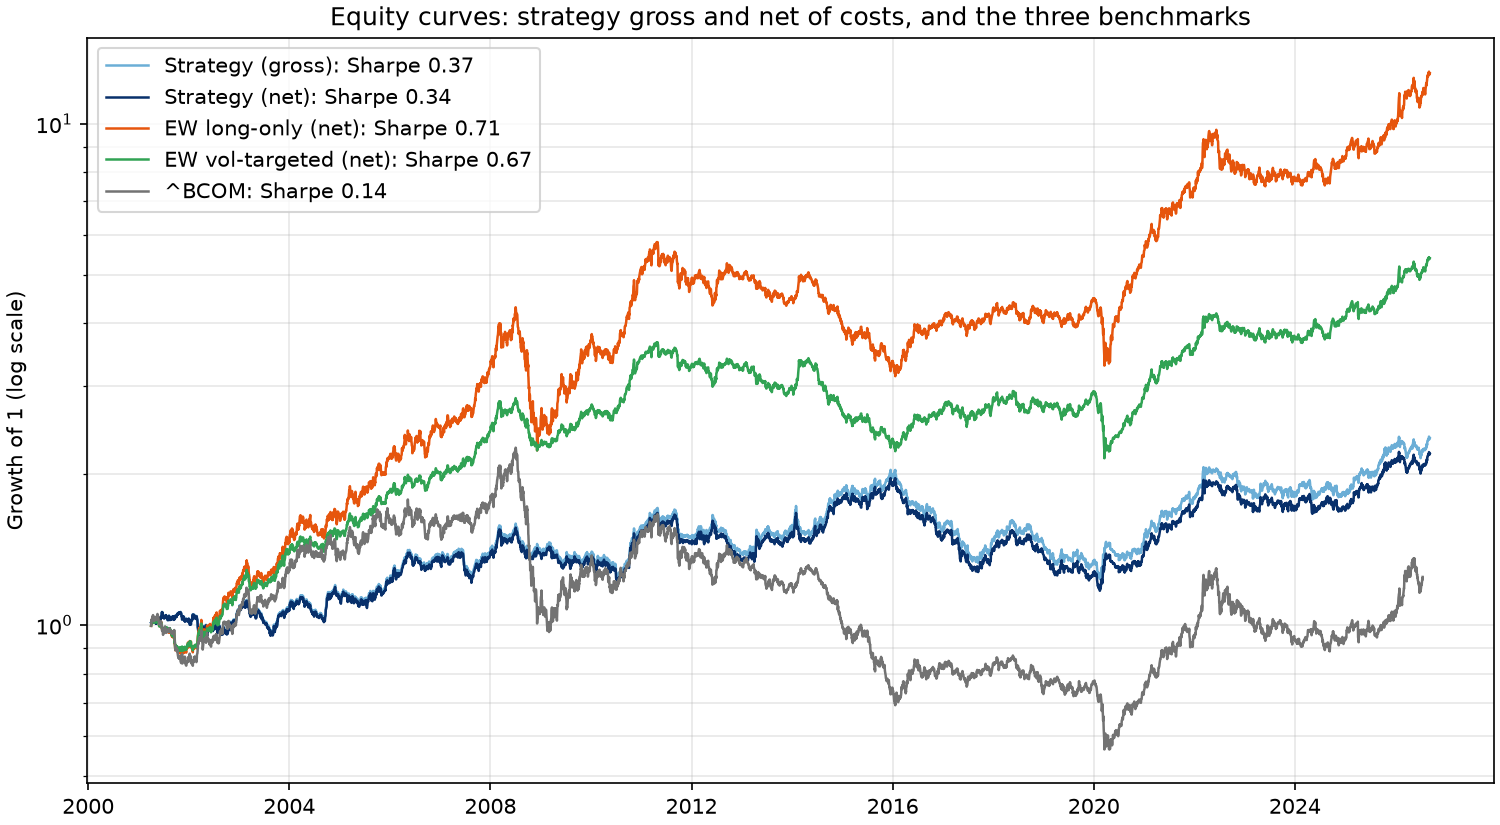

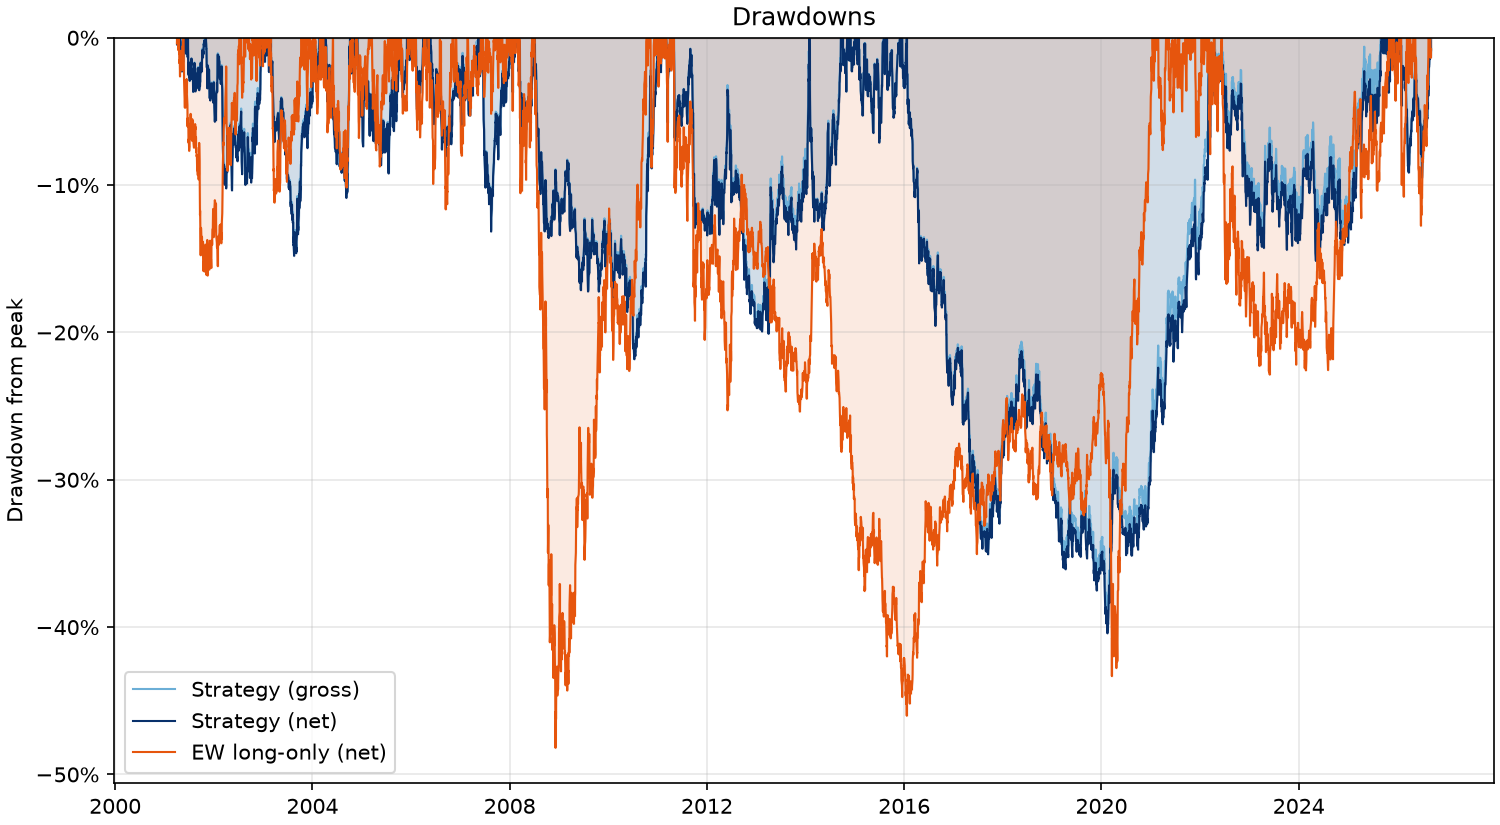

In [6]:
display(Image(FIGURES / "equity_curve.png"))
display(Image(FIGURES / "drawdown.png"))

In [7]:
wealth = wealth_index(returns)
drawdown = drawdown_curve(returns)
pd.DataFrame(
    {
        "growth of 1 (end of life)": wealth.ffill().iloc[-1],
        "worst drawdown": drawdown.min(),
        "worst drawdown date": drawdown.idxmin(),
    }
)

,growth of 1 (end of life),worst drawdown,worst drawdown date
Strategy (gross),2.358,-0.395,2020-02-14
Strategy (net),2.196,-0.404,2020-02-14
EW long-only (net),12.612,-0.482,2008-12-05
EW vol-targeted (net),5.391,-0.413,2020-03-18
^BCOM,1.247,-0.750,2020-03-18


## 5. Robustness: 192 trials, costs, lag, in sample and out of sample, sub-periods

The grid cache holds every trial at every cost. The default's place in it, the Sharpe
hurdle and the Deflated Sharpe Ratio are in `results/sweeps.md`; the figures are the
committed ones.

In [8]:
grid = pd.read_parquet(RESULTS / "grid.parquet")
at_cost = grid[grid["cost_bps"] == cfg.costs.cost_bps]
n_trials, sharpe_std = trial_stats(grid, cfg.costs.cost_bps)
default_row = at_cost[matches(at_cost, default_spec(cfg))]
print(f"{n_trials} trials at {cfg.costs.cost_bps:g} bps; std of their net Sharpe {sharpe_std:.3f}")
print(f"default trial net Sharpe {float(default_row['sharpe'].iloc[0]):.3f}")
at_cost["sharpe"].describe().to_frame("net Sharpe across the trials")

192 trials at 5 bps; std of their net Sharpe 0.156
default trial net Sharpe 0.340


,net Sharpe across the trials
count,192.000
mean,0.109
std,0.156
min,-0.286
25%,-0.007
50%,0.116
75%,0.233
max,0.472


# Robustness: trials, grid and sweeps

## Trials and the Deflated Sharpe Ratio

| Quantity | Value |
|---|---:|
| Trials (configurations evaluated) | 192 |
| Std of the trials' net Sharpe (5 bps) | 0.156 |
| Sharpe hurdle (expected max of the trials) | 0.431 |
| Probabilistic Sharpe of the default (net, vs 0) | 0.957 |
| Deflated Sharpe of the default (net) | 0.324 |

## The default among the trials (net Sharpe at 5 bps)

| Quantity | Value |
|---|---:|
| Minimum | -0.29 |
| Lower quartile | -0.01 |
| Median | 0.12 |
| Upper quartile | 0.23 |
| Maximum | 0.47 |
| Share of trials with Sharpe > 0 | 74.5% |
| Default | 0.34 |
| Default rank (1 = best) | 12 of 192 |
| Best trial | L 252 / vol 120 rolling / daily / skip 0 / lag 1 |
| Worst trial | L 63 / vol 20 rolling / daily / skip 0 / lag 2 |

## Cost sweep (default configuration; 0 bps is the gross result)

| Cost (bps) | Ann. return | Sharpe | Max drawdown | Grid median Sharpe | Grid share Sharpe > 0 |
|---:|---:|---:|---:|---:|---:|
| 0 | 3.43% | 0.37 | -39.46% | 0.20 | 96.35% |
| 5 | 3.14% | 0.34 | -40.42% | 0.12 | 74.48% |
| 10 | 2.85% | 0.31 | -41.36% | 0.02 | 54.69% |
| 20 | 2.28% | 0.26 | -43.21% | -0.11 | 36.46% |

## Lag sweep (default configuration)

| Lag (days) | Sharpe gross | Sharpe net | Ann. return net | Grid median Sharpe net |
|---:|---:|---:|---:|---:|
| 1 | 0.37 | 0.34 | 3.14% | 0.15 |
| 2 | 0.31 | 0.28 | 2.51% | 0.07 |


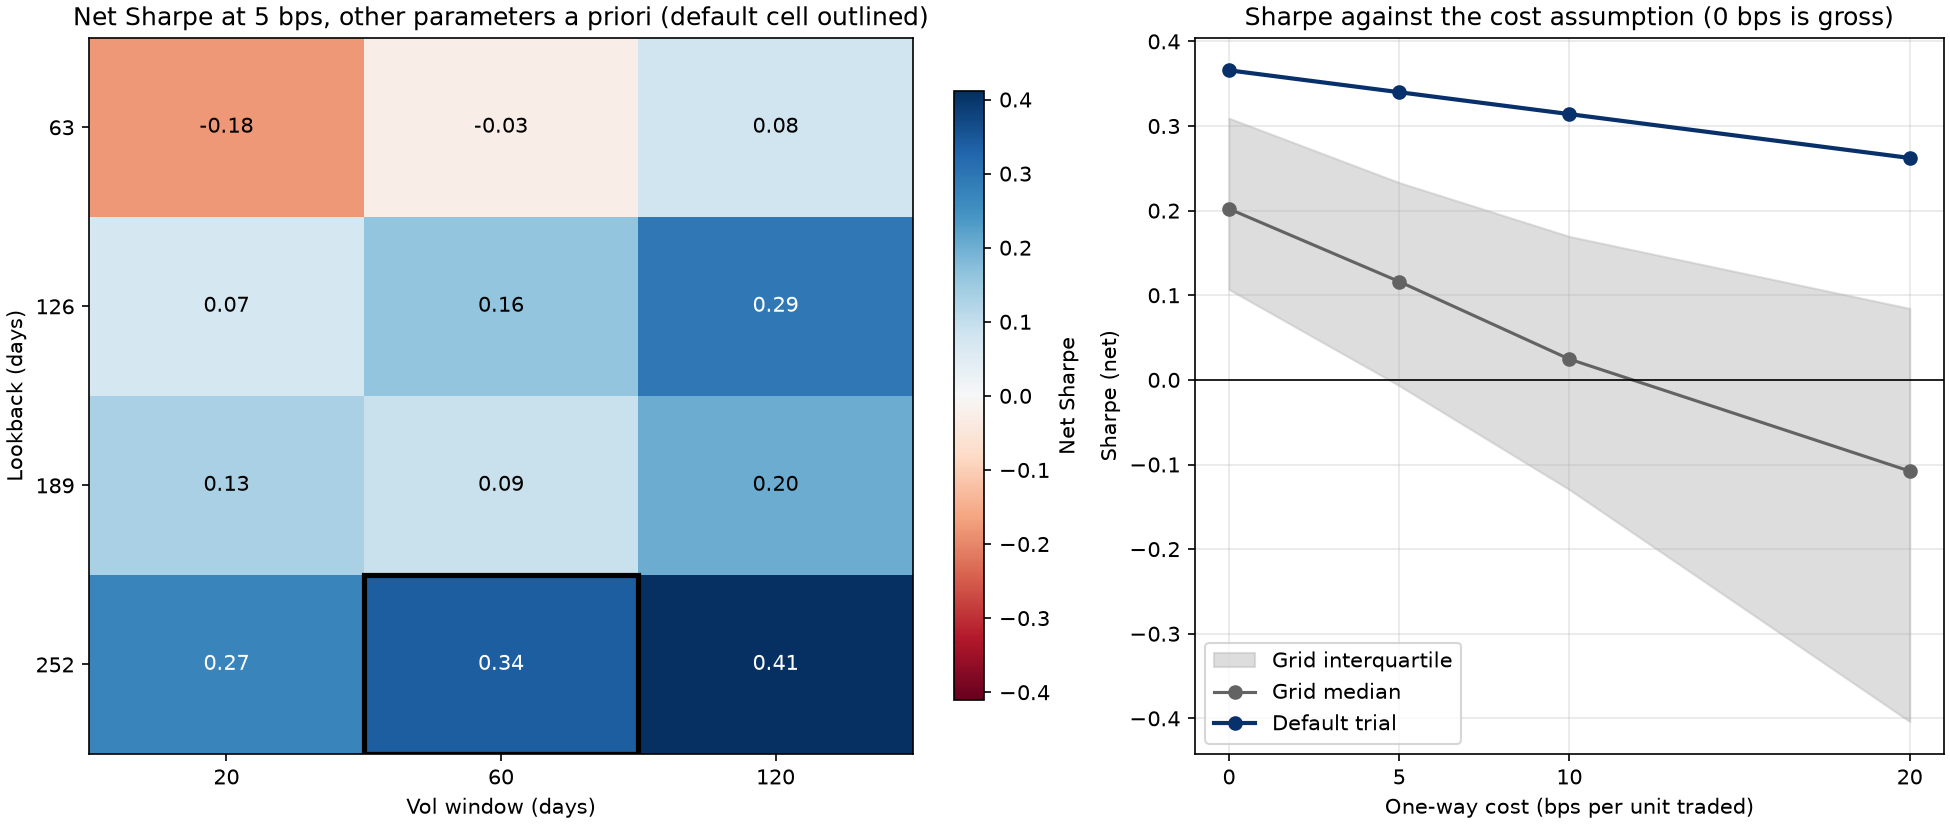

In [9]:
display(Markdown((RESULTS / "sweeps.md").read_text()))
display(Image(FIGURES / "param_sensitivity.png"))

# In-sample / out-of-sample selection

The lookback `L` is selected on the in-sample net Sharpe ratio (each trial's life up to 2012-12-31, at 5 bps), every other parameter at its a-priori default, and then measured out of sample (2013-01-01 to the end of the data). Only `L` is selected. The headline result stays the a-priori default; this table shows what selecting would have done.

| Lookback | Sharpe IS | Sharpe OOS | IS - OOS | Days IS | Days OOS | Selected | Default |
|---:|---:|---:|---:|---:|---:|---|---|
| 63 | 0.18 | -0.21 | 0.39 | 3156 | 3442 | - | - |
| 126 | 0.27 | 0.07 | 0.19 | 3093 | 3442 | - | - |
| 189 | -0.01 | 0.19 | -0.20 | 3030 | 3442 | - | - |
| 252 | 0.29 | 0.38 | -0.08 | 2968 | 3442 | yes | yes |

## Summary

| Quantity | Value |
|---|---:|
| Selected lookback | 252 |
| Selected: Sharpe in sample | 0.29 |
| Selected: Sharpe out of sample | 0.38 |
| Selected: degradation (IS - OOS) | -0.08 |
| A-priori lookback | 252 |
| A-priori: Sharpe in sample | 0.29 |
| A-priori: Sharpe out of sample | 0.38 |
| A-priori: degradation (IS - OOS) | -0.08 |
| Out of sample, selected minus a-priori | +0.00 |


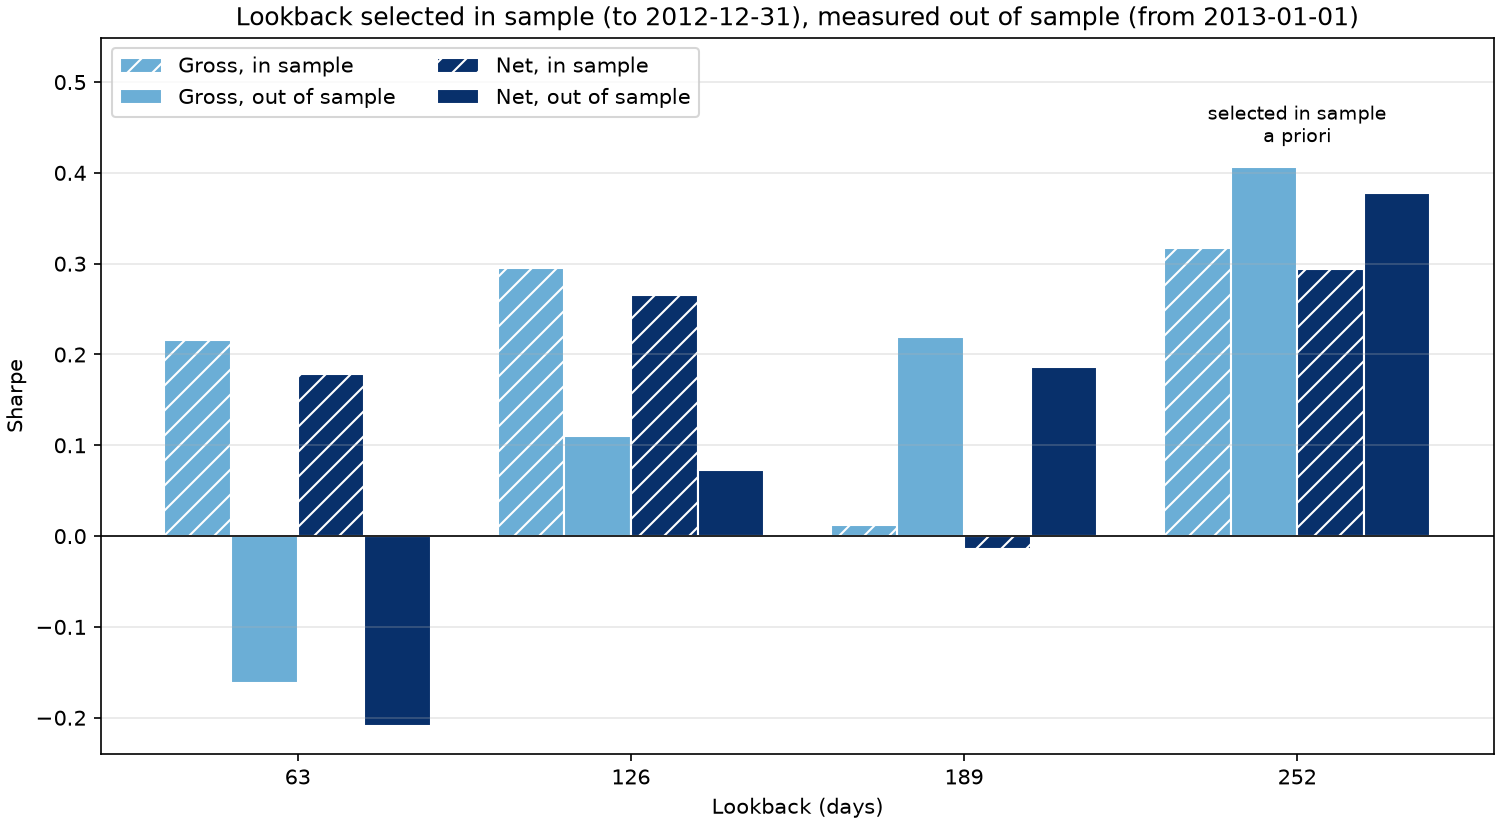

In [10]:
display(Markdown((RESULTS / "is_oos.md").read_text()))
display(Image(FIGURES / "is_oos.png"))

# Sub-periods

## Calendar blocks (fixed a priori)

| Block | Series | First day | Last day | Days | Ann. return | Ann. vol | Sharpe |
|---|---|---|---|---:|---:|---:|---:|
| 2000-2007 | Strategy (gross) | 2001-04-02 | 2007-12-31 | 1709 | 5.14% | 10.15% | 0.54 |
| 2000-2007 | Strategy (net) | 2001-04-02 | 2007-12-31 | 1709 | 4.86% | 10.15% | 0.52 |
| 2000-2007 | EW long-only (net) | 2001-04-02 | 2007-12-31 | 1709 | 19.11% | 14.01% | 1.32 |
| 2000-2007 | EW vol-targeted (net) | 2001-04-02 | 2007-12-31 | 1709 | 14.05% | 10.29% | 1.33 |
| 2000-2007 | ^BCOM | 2001-04-02 | 2007-12-31 | 1695 | 8.73% | 15.33% | 0.62 |
| 2008-2013 | Strategy (gross) | 2008-01-02 | 2013-12-31 | 1511 | 1.99% | 11.14% | 0.23 |
| 2008-2013 | Strategy (net) | 2008-01-02 | 2013-12-31 | 1511 | 1.75% | 11.15% | 0.21 |
| 2008-2013 | EW long-only (net) | 2008-01-02 | 2013-12-31 | 1511 | 5.29% | 19.85% | 0.36 |
| 2008-2013 | EW vol-targeted (net) | 2008-01-02 | 2013-12-31 | 1511 | 3.21% | 10.65% | 0.35 |
| 2008-2013 | ^BCOM | 2008-01-02 | 2013-12-31 | 1511 | -6.23% | 19.91% | -0.22 |
| 2014-2019 | Strategy (gross) | 2014-01-02 | 2019-12-31 | 1508 | -2.74% | 10.95% | -0.20 |
| 2014-2019 | Strategy (net) | 2014-01-02 | 2019-12-31 | 1508 | -3.07% | 10.95% | -0.23 |
| 2014-2019 | EW long-only (net) | 2014-01-02 | 2019-12-31 | 1508 | 0.04% | 11.66% | 0.06 |
| 2014-2019 | EW vol-targeted (net) | 2014-01-02 | 2019-12-31 | 1508 | -0.19% | 10.49% | 0.03 |
| 2014-2019 | ^BCOM | 2014-01-02 | 2019-12-31 | 1507 | -7.11% | 12.31% | -0.54 |
| 2020-present | Strategy (gross) | 2020-01-02 | 2026-09-07 | 1682 | 8.86% | 11.06% | 0.82 |
| 2020-present | Strategy (net) | 2020-01-02 | 2026-09-07 | 1682 | 8.55% | 11.07% | 0.80 |
| 2020-present | EW long-only (net) | 2020-01-02 | 2026-09-07 | 1682 | 16.81% | 16.23% | 1.04 |
| 2020-present | EW vol-targeted (net) | 2020-01-02 | 2026-09-07 | 1682 | 9.66% | 11.18% | 0.88 |
| 2020-present | ^BCOM | 2020-01-02 | 2026-07-17 | 1643 | 7.72% | 16.44% | 0.54 |

## Calendar years (compounded return)

| Year | Strategy (gross) | Strategy (net) | EW long-only (net) | EW vol-targeted (net) | ^BCOM |
|---|---:|---:|---:|---:|---:|
| 2001 | 3.05% | 2.92% | -9.73% | -9.31% | -15.51% |
| 2002 | 2.94% | 2.61% | 33.92% | 28.23% | 23.87% |
| 2003 | 1.46% | 1.15% | 20.74% | 19.48% | 22.66% |
| 2004 | 6.08% | 5.90% | 12.90% | 9.56% | 7.64% |
| 2005 | 7.59% | 7.32% | 31.10% | 21.26% | 17.54% |
| 2006 | 12.03% | 11.74% | 15.25% | 9.13% | -2.71% |
| 2007 | 2.05% | 1.70% | 31.49% | 21.07% | 11.09% |
| 2008 | 0.07% | -0.06% | -21.61% | -5.38% | -36.61% |
| 2009 | -2.19% | -2.32% | 43.12% | 17.26% | 18.71% |
| 2010 | 14.91% | 14.65% | 40.76% | 27.31% | 16.67% |
| 2011 | -5.20% | -5.33% | -6.89% | -4.95% | -13.37% |
| 2012 | -7.11% | -7.51% | 2.60% | -0.85% | -1.14% |
| 2013 | 13.62% | 13.24% | -9.68% | -9.22% | -9.58% |
| 2014 | 17.57% | 17.06% | -12.24% | -10.62% | -17.03% |
| 2015 | 6.05% | 5.85% | -14.08% | -10.73% | -24.70% |
| 2016 | -21.39% | -21.62% | 20.65% | 14.64% | 11.39% |
| 2017 | -4.57% | -4.98% | 5.17% | 4.77% | 0.75% |
| 2018 | -1.99% | -2.26% | -6.14% | -5.79% | -12.99% |
| 2019 | -7.62% | -8.03% | 11.62% | 9.48% | 5.44% |
| 2020 | 11.34% | 10.83% | 24.73% | -0.97% | -3.51% |
| 2021 | 19.67% | 19.51% | 31.99% | 22.55% | 27.06% |
| 2022 | 5.27% | 5.05% | 11.29% | 10.03% | 13.75% |
| 2023 | -2.82% | -3.13% | -5.61% | -4.12% | -12.55% |
| 2024 | -0.94% | -1.24% | 10.62% | 9.84% | 0.11% |
| 2025 | 24.92% | 24.60% | 15.65% | 13.32% | 11.07% |
| 2026 | 4.47% | 4.26% | 27.51% | 16.12% | 19.77% |

## Rolling 3-year Sharpe ratio

Trailing 756 observations of each series; a window is dated by its last day.

| Series | Windows | Share > 0 | Min | Min ends | Max | Max ends | Last | Last ends |
|---|---:|---:|---:|---|---:|---|---:|---|
| Strategy (gross) | 5655 | 80.90% | -1.07 | 2019-01-24 | 1.30 | 2022-03-23 | 0.77 | 2026-09-07 |
| Strategy (net) | 5655 | 78.71% | -1.10 | 2019-01-24 | 1.27 | 2022-03-23 | 0.75 | 2026-09-07 |
| EW long-only (net) | 5655 | 80.18% | -1.25 | 2016-01-20 | 1.80 | 2008-02-28 | 1.19 | 2026-09-07 |
| EW vol-targeted (net) | 5655 | 78.53% | -1.16 | 2016-01-20 | 1.86 | 2004-11-25 | 1.16 | 2026-09-07 |
| ^BCOM | 5601 | 50.19% | -1.71 | 2016-01-20 | 1.37 | 2004-10-26 | 0.63 | 2026-07-17 |

## Regimes: calm versus stress (hindsight)

**Hindsight caveat.** A day is labelled *stress* when the equal-weight basket's trailing volatility is above a quantile of its full-sample distribution. That threshold was only known once the sample had ended, so this view describes where the returns came from; it is not a rule anyone could have traded.
Here: the equal-weight long-only basket's trailing 60-day volatility above its full-sample 75% quantile.

| Regime | Series | Days | Share of days | Ann. return | Ann. vol | Sharpe |
|---|---|---:|---:|---:|---:|---:|
| calm | Strategy (gross) | 4866 | 75.91% | 6.38% | 10.84% | 0.62 |
| calm | Strategy (net) | 4866 | 75.91% | 6.06% | 10.84% | 0.60 |
| calm | EW long-only (net) | 4866 | 75.91% | 12.58% | 12.95% | 0.98 |
| calm | EW vol-targeted (net) | 4866 | 75.91% | 8.62% | 10.49% | 0.84 |
| calm | ^BCOM | 4815 | 75.76% | 2.71% | 13.48% | 0.27 |
| stress | Strategy (gross) | 1544 | 24.09% | -5.34% | 10.76% | -0.46 |
| stress | Strategy (net) | 1544 | 24.09% | -5.54% | 10.76% | -0.48 |
| stress | EW long-only (net) | 1544 | 24.09% | 4.10% | 22.24% | 0.29 |
| stress | EW vol-targeted (net) | 1544 | 24.09% | 1.44% | 11.19% | 0.18 |
| stress | ^BCOM | 1541 | 24.24% | -4.64% | 22.72% | -0.10 |


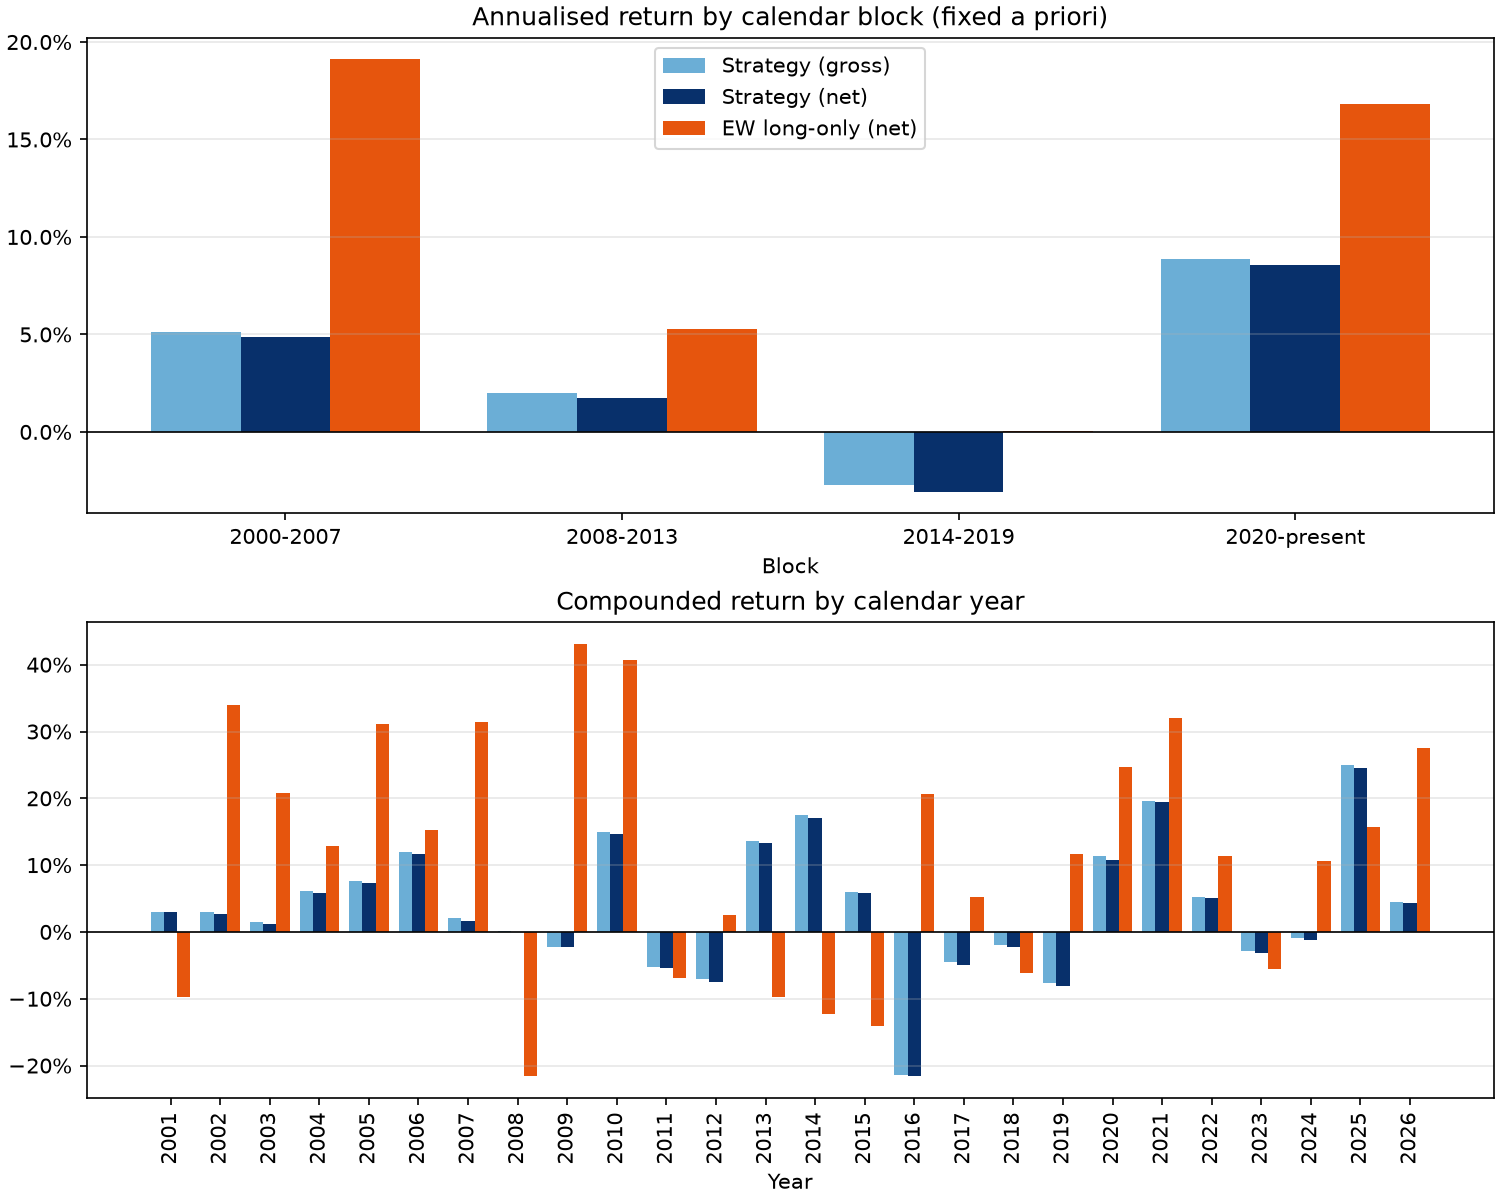

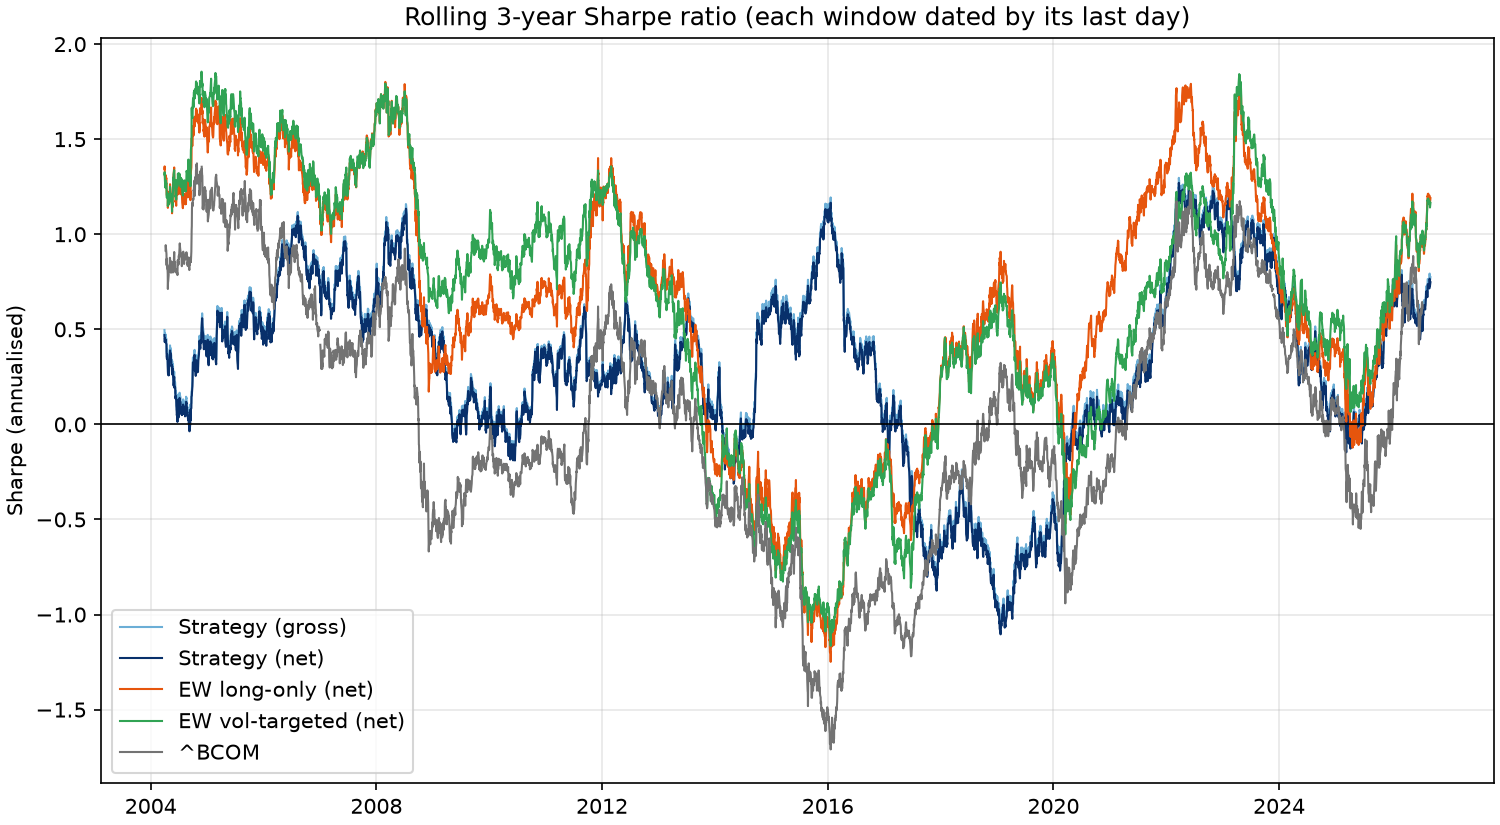

In [11]:
display(Markdown((RESULTS / "subperiods.md").read_text()))
display(Image(FIGURES / "returns_by_subperiod.png"))
display(Image(FIGURES / "rolling_sharpe.png"))

In [12]:
years = calendar_year_returns(returns)
pd.DataFrame(
    {
        "years up": (years > 0).sum(),
        "years down": (years < 0).sum(),
        "best year": years.idxmax(),
        "best": years.max(),
        "worst year": years.idxmin(),
        "worst": years.min(),
    }
)

,years up,years down,best year,best,worst year,worst
Strategy (gross),17,9,2025,0.249,2016,-0.214
Strategy (net),16,10,2025,0.246,2016,-0.216
EW long-only (net),18,8,2009,0.431,2008,-0.216
EW vol-targeted (net),16,10,2002,0.282,2015,-0.107
^BCOM,15,11,2021,0.271,2008,-0.366


## 6. Exposure

Gross and net leverage and the long and short counts over the life, from the positions the
backtest stage wrote. The cap is drawn on the figure; the table says whether it ever bound.

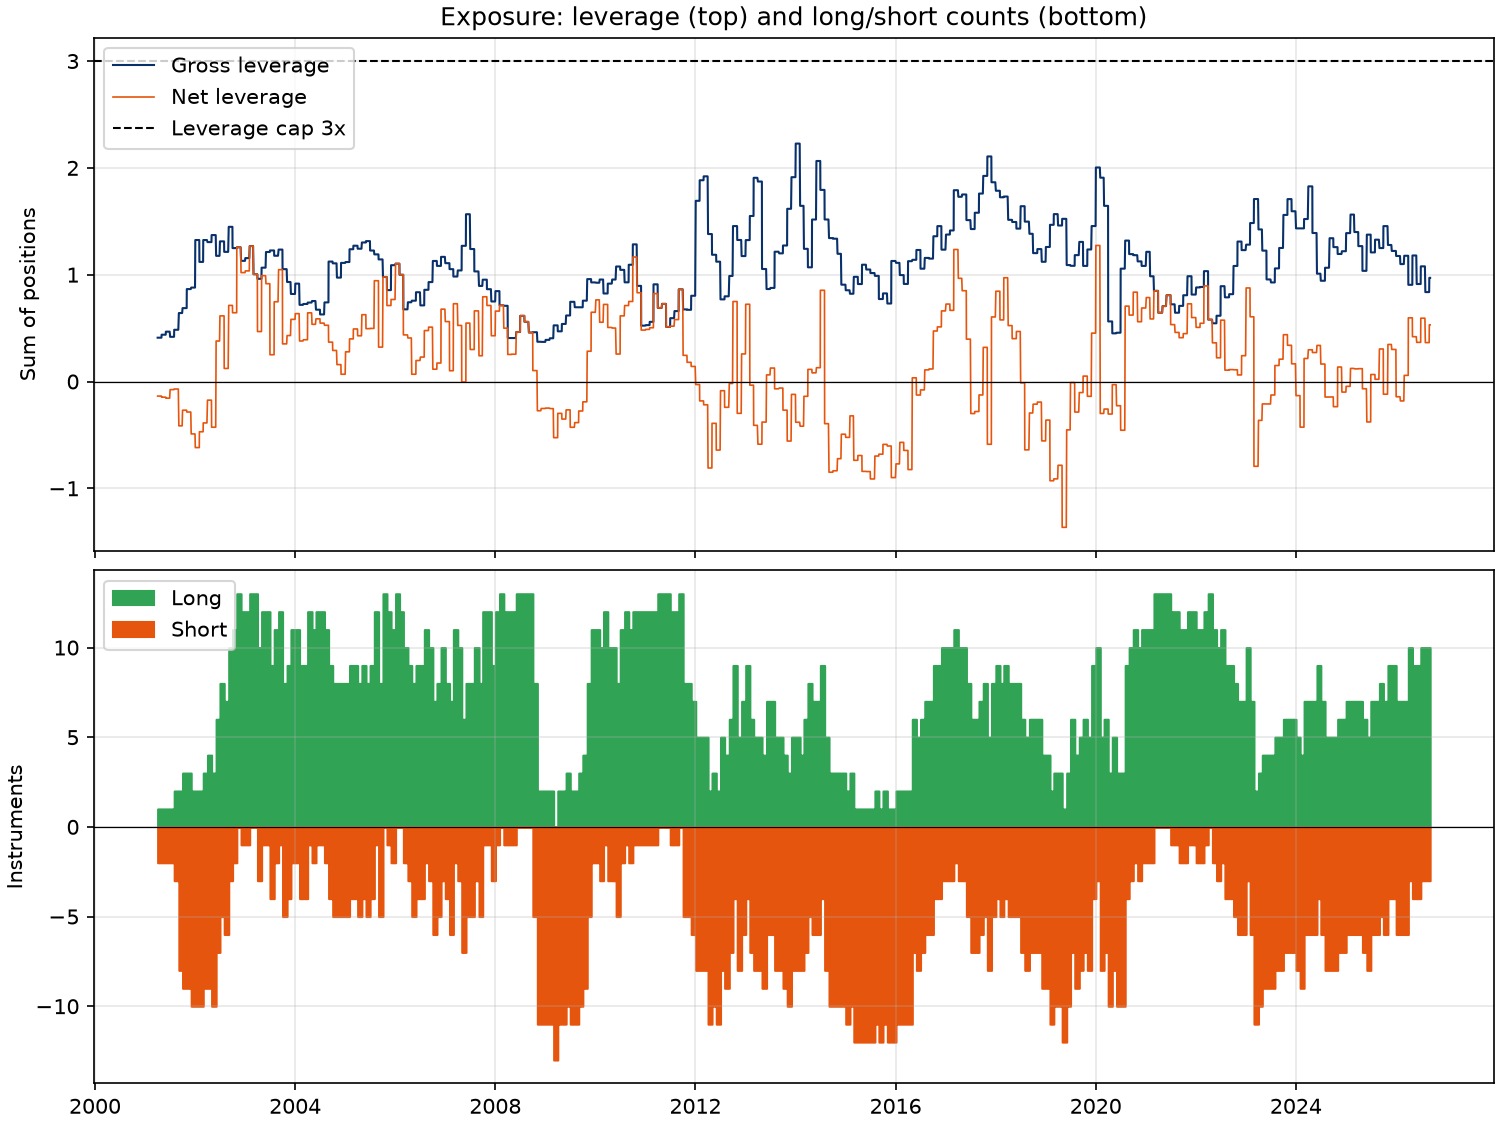

,over the strategy's life
leverage cap,3.000
max gross leverage,2.227
mean gross leverage,1.097
days at or above the cap,0.000
mean instruments long,7.429
mean instruments short,5.363


In [13]:
positions = pd.read_csv(RESULTS / "positions.csv", index_col="date", parse_dates=True)
positions = positions.loc[returns.index]
gross_leverage = positions.abs().sum(axis=1)
display(Image(FIGURES / "exposure.png"))
pd.Series(
    {
        "leverage cap": cfg.sizing.leverage_cap,
        "max gross leverage": gross_leverage.max(),
        "mean gross leverage": gross_leverage.mean(),
        "days at or above the cap": int((gross_leverage >= cfg.sizing.leverage_cap).sum()),
        "mean instruments long": (positions > 0).sum(axis=1).mean(),
        "mean instruments short": (positions < 0).sum(axis=1).mean(),
    },
    name="over the strategy's life",
).to_frame()

## 7. What to make of it

The README's Inference and Limitations sections are the conclusion: a small positive net
Sharpe, consistent with the published time-series-momentum literature, that the evidence
from this one basket cannot distinguish from selection luck once 192 trials are counted;
a long-only comparison flattered by front-month series that never pay the roll; and a
strategy that, on this data, lost money in the stress regime rather than earning its keep
there. The rigor checklist at the end of the README names the test behind each claim.